# Notebook 02 — Camera geometry, stereo depth and PnP

Companion to [Lecture 2](../02_sensors_and_perception.md) (§2–§4). We relate focal length to field of
view (2.3), plot the $Z^2$ growth of stereo depth error (2.4, Figure 2.1), check the body-to-optical
rotation, and reproduce the two-fold IPPE ambiguity of planar PnP (2.5).

In [1]:
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
import cv2

## 1. Pinhole projection and field of view (§2)
$f_x = (W/2)/\tan(\theta/2)$: for SAURCON's 640 px, 1.204 rad camera, $f_x = 465.7$ px.

fx = 465.7 px


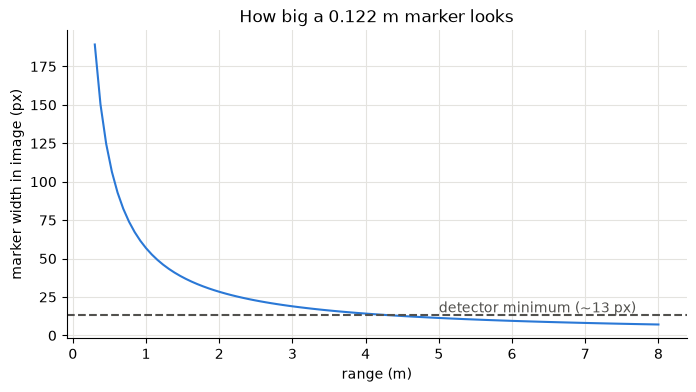

In [2]:
W, H, fov = 640, 400, 1.204
fx = (W/2)/np.tan(fov/2); K = np.array([[fx, 0, W/2], [0, fx, H/2], [0, 0, 1.0]])
print(f"fx = {fx:.1f} px")
side = 0.12192                       # black square of the simulated ArUco marker (m)
Z = np.linspace(0.3, 8, 100)
plt.plot(Z, fx*side/Z, color=BLUE); plt.axhline(13, color=GREY, ls='--')
plt.text(5, 15, 'detector minimum (~13 px)', color=GREY)
plt.xlabel('range (m)'); plt.ylabel('marker width in image (px)'); plt.title('How big a 0.122 m marker looks'); plt.show()

## 2. Stereo depth error grows with range squared (§3)
$Z = fB/d$, so $\sigma_Z \approx Z^2\sigma_d/(fB)$ (2.4). OAK-D Lite: $B$ = 75 mm.

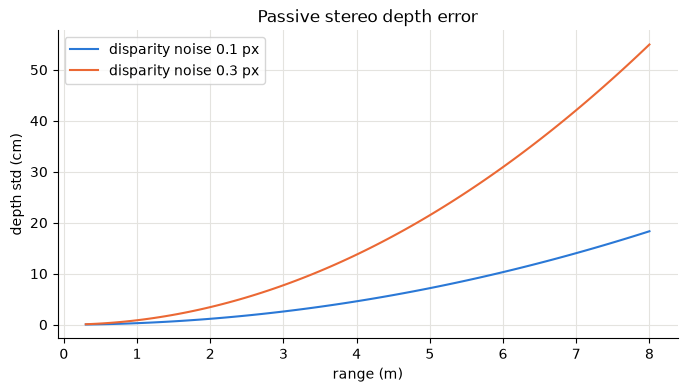

at 1 m and 4 m with 0.1 px: [0.29, 4.58] cm


In [3]:
B = 0.075
for sd, c in ((0.1, BLUE), (0.3, ORANGE)):
    plt.plot(Z, 100*Z**2*sd/(fx*B), color=c, label=f'disparity noise {sd} px')
plt.xlabel('range (m)'); plt.ylabel('depth std (cm)'); plt.legend(); plt.title('Passive stereo depth error'); plt.show()
print('at 1 m and 4 m with 0.1 px:', [round(100*z**2*0.1/(fx*B), 2) for z in (1, 4)], 'cm')

## 3. Optical frame vs body frame (§2)
Body: $x$ forward, $y$ left, $z$ up. Optical: $x$ right, $y$ down, $z$ forward. The fixed rotation between them
is ${}^{B}\mathbf C_{C}$ of Lecture 0, problem 0.4.

In [4]:
R_body_from_optical = np.array([[0, 0, 1], [-1, 0, 0], [0, -1, 0]])
p_optical = np.array([0.1, 0.0, 2.0])      # 10 cm right of the optical axis, 2 m ahead
print('same point in body frame:', R_body_from_optical @ p_optical)

same point in body frame: [ 2.  -0.1  0. ]


## 4. PnP on a square marker, and the two IPPE solutions (§4)
Project the marker's corners with a known pose, add pixel noise, and solve (2.5) with IPPE [Collins14].

In [5]:
h = side/2
obj = np.array([[-h, h, 0], [h, h, 0], [h, -h, 0], [-h, -h, 0]], np.float32)

def solve(rng_m, yaw_deg, noise_px, rng=np.random.default_rng(0)):
    rvec = cv2.Rodrigues(np.array([[np.cos(np.radians(yaw_deg)), 0, np.sin(np.radians(yaw_deg))],
                                   [0, 1, 0],
                                   [-np.sin(np.radians(yaw_deg)), 0, np.cos(np.radians(yaw_deg))]]))[0]
    tvec = np.array([[0.0], [0.0], [rng_m]])
    img, _ = cv2.projectPoints(obj, rvec, tvec, K, None)
    img = img.reshape(-1, 2) + rng.normal(0, noise_px, (4, 2))
    n, rvecs, tvecs, err = cv2.solvePnPGeneric(obj, img.astype(np.float32), K, None,
                                               flags=cv2.SOLVEPNP_IPPE_SQUARE)
    yaws = [np.degrees(np.arctan2(cv2.Rodrigues(r)[0][0, 2], cv2.Rodrigues(r)[0][2, 2])) for r in rvecs]
    return yaws, np.ravel(err)

for rng_m in (1.0, 3.0, 5.0):
    yaws, err = solve(rng_m, 10, 0.3)
    print(f"range {rng_m} m, true yaw 10 deg: solutions {np.round(yaws, 1)} deg, reprojection errors {np.round(err, 3)} px")

range 1.0 m, true yaw 10 deg: solutions [ 10. -10.] deg, reprojection errors [0.125 0.486] px
range 3.0 m, true yaw 10 deg: solutions [ 13.9 -14. ] deg, reprojection errors [0.085 0.108] px
range 5.0 m, true yaw 10 deg: solutions [-9.5  9.5] deg, reprojection errors [0.036 0.039] px


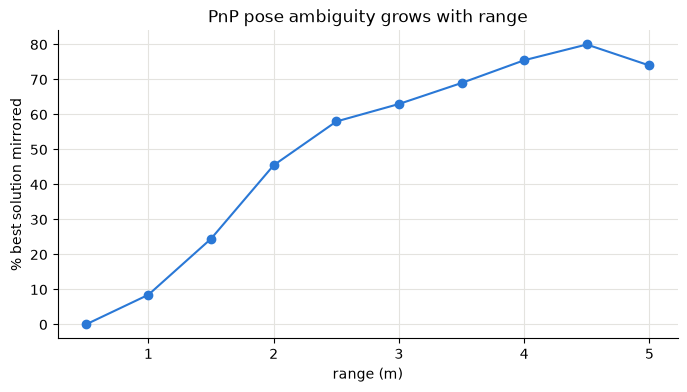

In [6]:
# How often is the best solution the wrong one (mirrored)? Monte Carlo over range.
ranges = np.linspace(0.5, 5, 10); wrong = []
gen = np.random.default_rng(1)
for r in ranges:
    bad = 0
    for _ in range(200):
        yaws, err = solve(r, 10, 0.3, gen)
        bad += abs(yaws[0] - 10) > 5
    wrong.append(bad/200)
plt.plot(ranges, 100*np.array(wrong), color=BLUE, marker='o')
plt.xlabel('range (m)'); plt.ylabel('% best solution mirrored'); plt.title('PnP pose ambiguity grows with range'); plt.show()

## Problems
Lecture 2's problems **2.2** and **2.4** are done in this notebook.

**N2.1** Increase the image width to 1280 px (same field of view). How does the ambiguity curve change, and why?

**N2.2** Implement SAURCON's rejection rule (two solutions more than 15° apart with an error ratio below 2) and
plot the fraction of detections it discards against range.

**N2.3** Compute the vehicle-position error caused by a mirrored solution at 3 m, and compare with the
first-order estimate of problem 2.3.